In [1]:
# Split a real-match volleyball video into segments at referee-whistle timestamps.
#
# Everything runs in-process through PyAV: the only ffmpeg on this machine is the snap
# build, which cannot write to stdout/pipes (verified), so subprocess + pipes is not an
# option. PyAV links libav* directly and sidesteps it entirely.
import json
import sys
from fractions import Fraction
from pathlib import Path

import av
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Audio, display
from scipy.io import wavfile
from scipy.signal import medfilt, stft
from tqdm.auto import tqdm

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print(f"root={ROOT}  av={av.__version__}  numpy={np.__version__}  pandas={pd.__version__}")

root=/home/bugslayer/Documents/research/VolleyVision  av=18.1.0  numpy=2.5.2  pandas=3.0.5


/home/bugslayer/Documents/research/VolleyVision/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
VIDEO_PATH = Path(
    "/home/bugslayer/Downloads/volley video footage/data/"
    "videoplayback.1773931843922.publer.com-00.00.00.000-00.10.03.976-"
    "00.06.08.875-00.10.04.033.mp4"
)

# Tuning order, when pointing this at new footage:
#   1. Run through the peak_hz histogram below. If the whistle line sits outside the
#      dashed band guides on the spectrogram, fix f_lo/f_hi FIRST -- nothing else matters
#      until the band is right.
#   2. Too many events -> raise score_floor (0.35 -> 0.5) and/or min_dur_s.
#   3. Missed quiet whistles -> lower score_floor and level_margin_db.
#   4. One whistle split into three events -> raise merge_gap_s.
#   5. Only then touch the segmentation params.
# Every function below takes params explicitly, so editing this cell and re-running
# cells 6-9 is the whole tuning loop -- no kernel restart.
PARAMS = {
    # --- audio / STFT (rarely changed) ---
    "sr": 16000,          # Nyquist 8 kHz covers the whistle fundamental and its partner tone
    "n_fft": 1024,        # 64 ms window, 15.6 Hz bins
    "hop": 160,           # 10 ms frames -- ~3x finer than the 33 ms video frame

    # --- whistle band ---
    # Measured on this footage: the referee uses a pealess (Fox 40 class) whistle whose
    # spectrum is a dual tone at ~3530 Hz + ~3910 Hz, rock steady across every blast.
    # 3300-4200 Hz brackets both. Widen to 2000-5200 for unknown footage, then narrow
    # using the peak_hz histogram -- the wide band also catches crowd whistles around
    # 2.0-2.7 kHz, which is exactly what the narrow band is there to reject.
    "f_lo": 3300.0,
    "f_hi": 4200.0,
    "full_lo": 100.0,     # denominator band for band_ratio
    "full_hi": 8000.0,

    # --- detection sensitivity: THE main knobs ---
    "score_floor": 0.35,      # raise -> fewer false positives
    "mad_k": 6.0,             # adaptive term; score_floor usually binds instead
    "hysteresis_ratio": 0.5,  # lower -> longer, less fragmented events
    "level_margin_db": 12.0,  # dB above the noise floor at which level saturates
    "noise_floor_pct": 50.0,
    "score_medfilt": 5,       # odd; 5 frames = 50 ms de-speckle

    # --- event shaping ---
    "min_dur_s": 0.25,        # a real blast is 0.3-1.5 s; rejects impact clicks and squeaks
    "merge_gap_s": 0.12,      # keep < 0.25 s so a double-blast stays two events;
                              # raise to ~0.5 to fuse them into one cut
    "min_prom_db": 18.0,      # in-band peak-to-median prominence
    # NOTE: there is deliberately no peak_hz IQR filter here. See detect_events.

    # --- whistle template (the scream rejector) ---
    # A pealess referee whistle sounds two chambers at once, so its spectrum is a tone
    # PAIR at a fixed frequency ratio (~1.106 here: 3530 + 3910 Hz). A shout or scream is
    # a single harmonic stack and has no companion tone at that ratio. The ratio is
    # learned from the clip's own loudest blasts rather than hardcoded, so a different
    # whistle model self-tunes instead of silently failing.
    "template_seeds": 5,             # top-N events by score_max used to learn the pair
    "template_min_sep_hz": 150.0,    # min separation for the companion peak
    "template_ratio_iqr_max": 0.02,  # seeds disagreeing more than this -> gate disabled
    "dual_tol_bins": 2,              # +/- bins searched around the predicted companion
    # dual_min sits on a wide plateau: on this footage anything in 0.06-0.15 makes the
    # same call (the scream measures 0.034, the weakest true whistle 0.177).
    "dual_min": 0.10,

    # --- segmentation: every whistle is a boundary, segments tile the whole video ---
    "pre_roll_s": 0.5,        # keep this much footage before each whistle
    "min_segment_s": 2.0,     # shorter fragments are absorbed into the preceding segment

    # --- output ---
    "out_dir": str(VIDEO_PATH.parent / "splits"),
    "stream_copy": False,     # True = fast but cuts snap to H.264 keyframes (see cut_segment)
    "crf": 20,
    "preset": "veryfast",
    "audio_bitrate": 128_000,
}

OUT_DIR = Path(PARAMS["out_dir"])
print(OUT_DIR)

/home/bugslayer/Downloads/volley video footage/data/splits


In [3]:
def probe_video(path: str | Path) -> dict:
    """PyAV analogue of VBallNet.get_video_metadata that also reports the audio stream."""
    with av.open(str(path)) as container:
        v = container.streams.video[0]
        audio = container.streams.audio
        meta = {
            "path": str(path),
            "width": v.codec_context.width,
            "height": v.codec_context.height,
            "fps": float(v.average_rate),
            "frames": v.frames,
            "duration_s": float(container.duration / av.time_base),
            "video_codec": v.codec_context.name,
            "has_audio": bool(audio),
        }
        if audio:
            a = audio[0]
            meta |= {
                "audio_codec": a.codec_context.name,
                "audio_rate": a.codec_context.rate,
                "audio_layout": a.layout.name,
            }
    return meta


meta = probe_video(VIDEO_PATH)
assert meta["has_audio"], "no audio stream -- whistle detection is impossible"
meta

{'path': '/home/bugslayer/Downloads/volley video footage/data/videoplayback.1773931843922.publer.com-00.00.00.000-00.10.03.976-00.06.08.875-00.10.04.033.mp4',
 'width': 640,
 'height': 360,
 'fps': 29.994260522444733,
 'frames': 7053,
 'duration_s': 235.158008,
 'video_codec': 'h264',
 'has_audio': True,
 'audio_codec': 'aac',
 'audio_rate': 44100,
 'audio_layout': 'stereo'}

In [4]:
def load_audio_mono(path: str | Path, sr: int) -> np.ndarray:
    """Decode the audio track to a mono float32 waveform at `sr` Hz."""
    chunks: list[np.ndarray] = []
    with av.open(str(path)) as container:
        stream = container.streams.audio[0]
        stream.thread_type = "AUTO"
        resampler = av.AudioResampler(format="flt", layout="mono", rate=sr)
        for frame in container.decode(stream):
            for out in resampler.resample(frame):
                chunks.append(out.to_ndarray().reshape(-1))
        # Flushing matters: skip it and the tail of the clip is silently dropped.
        for out in resampler.resample(None):
            chunks.append(out.to_ndarray().reshape(-1))
    return np.concatenate(chunks).astype(np.float32)

In [5]:
audio = load_audio_mono(VIDEO_PATH, PARAMS["sr"])
audio_dur = len(audio) / PARAMS["sr"]
peak = float(np.abs(audio).max())

print(f"{len(audio):,} samples  {audio_dur:.3f} s  peak={peak:.3f}")
print(f"container duration {meta['duration_s']:.3f} s  (delta {audio_dur - meta['duration_s']:+.3f} s)")
assert 0.0 < peak <= 1.0, "all-zero or clipped audio -- check the resampler format/flush"
assert abs(audio_dur - meta["duration_s"]) < 0.5, "decoded audio length disagrees with the container"

3,762,004 samples  235.125 s  peak=0.339
container duration 235.158 s  (delta -0.033 s)


In [6]:
def compute_features(audio: np.ndarray, sr: int, params: dict) -> dict:
    """STFT plus the three per-frame whistle features, each normalised to [0, 1].

    score = band_ratio * tonality * level has AND semantics: a detection needs the frame
    to be narrowband AND tonal AND loud. That triple is the whistle signature; any single
    feature on its own fires on crowd noise, ball impacts or PA hiss.
    """
    n_fft, hop = params["n_fft"], params["hop"]
    f, t, Z = stft(
        audio, fs=sr, window="hann", nperseg=n_fft, noverlap=n_fft - hop,
        boundary=None, padded=False,
    )
    P = (np.abs(Z) ** 2).astype(np.float32)

    band = (f >= params["f_lo"]) & (f <= params["f_hi"])
    full = (f >= params["full_lo"]) & (f <= params["full_hi"])
    Pb, fb = P[band], f[band]

    band_power = Pb.sum(0)
    band_ratio = band_power / (P[full].sum(0) + 1e-20)

    # Spectral flatness inside the band: 1 = white noise, -> 0 = pure tone.
    flatness = np.exp(np.log(Pb + 1e-20).mean(0)) / (Pb.mean(0) + 1e-20)
    tonality = np.clip(1.0 - flatness, 0.0, 1.0)

    peak_hz = fb[Pb.argmax(0)]
    prom_db = 10 * np.log10(Pb.max(0) / (np.median(Pb, axis=0) + 1e-20) + 1e-20)

    band_db = 10 * np.log10(band_power + 1e-20)
    # A single global percentile is fine for a few minutes from one venue and one mic.
    # For multi-hour footage swap this for a rolling percentile over +/-30 s.
    floor_db = float(np.percentile(band_db, params["noise_floor_pct"]))
    level = np.clip((band_db - floor_db) / params["level_margin_db"], 0.0, 1.0)

    score = medfilt((band_ratio * tonality * level).astype(np.float64), params["score_medfilt"])

    med = float(np.median(score))
    mad = float(np.median(np.abs(score - med))) * 1.4826
    # The floor guards the degenerate case: on whistle-free audio med + k*mad collapses
    # towards zero and every ambient frame would fire.
    thr_hi = max(params["score_floor"], med + params["mad_k"] * mad)
    thr_lo = params["hysteresis_ratio"] * thr_hi

    return {
        "f": f, "t": t, "P": P, "band_mask": band,
        "band_ratio": band_ratio, "tonality": tonality, "level": level,
        "peak_hz": peak_hz, "prom_db": prom_db, "band_db": band_db,
        "floor_db": floor_db, "score": score,
        "thr_hi": float(thr_hi), "thr_lo": float(thr_lo),
        "score_median": med, "score_mad": mad,
    }

23,507 STFT frames, 0.0100 s apart
noise floor -55.7 dB   score median=0.0000 mad=0.0000
thr_hi=0.350 (score_floor binds)   thr_lo=0.175


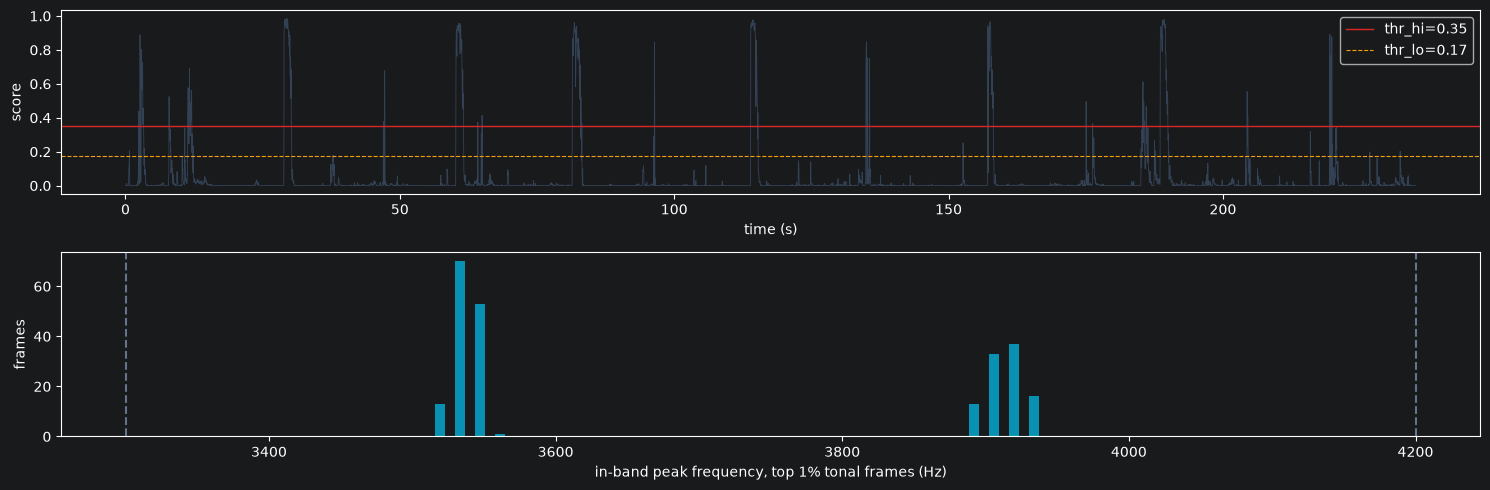

In [7]:
feat = compute_features(audio, PARAMS["sr"], PARAMS)
t, score = feat["t"], feat["score"]

print(f"{len(t):,} STFT frames, {t[1] - t[0]:.4f} s apart")
print(f"noise floor {feat['floor_db']:.1f} dB   score median={feat['score_median']:.4f} mad={feat['score_mad']:.4f}")
print(f"thr_hi={feat['thr_hi']:.3f} ({'score_floor' if feat['thr_hi'] <= PARAMS['score_floor'] else 'MAD'} binds)"
      f"   thr_lo={feat['thr_lo']:.3f}")

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(15, 5))
ax0.plot(t, score, lw=0.6, color="#334155")
ax0.axhline(feat["thr_hi"], color="#dc2626", lw=1.0, label=f"thr_hi={feat['thr_hi']:.2f}")
ax0.axhline(feat["thr_lo"], color="#f59e0b", lw=0.8, ls="--", label=f"thr_lo={feat['thr_lo']:.2f}")
ax0.set_xlabel("time (s)"); ax0.set_ylabel("score"); ax0.legend(loc="upper right")

# Band-picking aid: where does the energy actually sit on the loudest tonal frames?
loud = feat["band_ratio"] * feat["tonality"] > np.percentile(feat["band_ratio"] * feat["tonality"], 99.0)
ax1.hist(feat["peak_hz"][loud], bins=60, color="#0891b2")
ax1.axvline(PARAMS["f_lo"], color="#64748b", ls="--"); ax1.axvline(PARAMS["f_hi"], color="#64748b", ls="--")
ax1.set_xlabel("in-band peak frequency, top 1% tonal frames (Hz)"); ax1.set_ylabel("frames")
fig.tight_layout()

In [8]:
def _runs(mask: np.ndarray) -> list[tuple[int, int]]:
    """Half-open [start, end) index ranges of True runs."""
    padded = np.concatenate(([False], mask, [False]))
    edges = np.diff(padded.astype(np.int8))
    return list(zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)))


def detect_events(feat: dict, params: dict, fps: float) -> pd.DataFrame:
    """Schmitt-trigger the score, then shape the runs. Candidates only -- the timbre
    test that separates whistles from screams is applied afterwards by the template gate.
    """
    t, score = feat["t"], feat["score"]
    peak_hz, prom_db = feat["peak_hz"], feat["prom_db"]
    thr_hi, thr_lo = feat["thr_hi"], feat["thr_lo"]

    # Open on thr_hi, stay open down to thr_lo: captures the attack and decay of a blast
    # without fragmenting on its amplitude ripple.
    above_hi, above_lo = score > thr_hi, score > thr_lo
    runs = [(a, b) for a, b in _runs(above_lo) if above_hi[a:b].any()]

    merged: list[list[int]] = []
    for a, b in runs:
        if merged and (t[a] - t[merged[-1][1] - 1]) < params["merge_gap_s"]:
            merged[-1][1] = b
        else:
            merged.append([a, b])

    rows = []
    for a, b in merged:
        start_s, end_s = float(t[a]), float(t[b - 1])
        if end_s - start_s < params["min_dur_s"]:
            continue
        hz = peak_hz[a:b]
        # peak_hz_iqr is REPORTED but never filtered on, and must stay that way. On a
        # dual-tone whistle the dominant bin alternates between the two tones, so the IQR
        # measures the ~380 Hz tone spacing, not pitch instability -- every true whistle
        # here lands at 359-406 Hz. An earlier 400 Hz cutoff silently deleted the 28.87 s
        # blast. Timbre is judged by the template gate below instead.
        iqr = float(np.subtract(*np.percentile(hz, [75, 25])))
        prom = float(np.median(prom_db[a:b]))
        if prom < params["min_prom_db"]:
            continue
        rows.append({
            "start_s": start_s,
            "end_s": end_s,
            "duration_s": end_s - start_s,
            "peak_hz": float(np.median(hz)),
            "peak_hz_iqr": iqr,
            "prom_db": prom,
            "score_max": float(score[a:b].max()),
            "score_mean": float(score[a:b].mean()),
        })

    events = pd.DataFrame(rows, columns=[
        "start_s", "end_s", "duration_s", "peak_hz", "peak_hz_iqr",
        "prom_db", "score_max", "score_mean",
    ]).sort_values("start_s", ignore_index=True)
    events["frame"] = (events["start_s"] * fps).round().astype(int)
    return events

In [9]:
events_raw = detect_events(feat, PARAMS, meta["fps"])
print(f"{len(events_raw)} candidates over {audio_dur:.1f} s (pre-template)")
events_raw

10 candidates over 235.1 s (pre-template)


,start_s,end_s,duration_s,peak_hz,peak_hz_iqr,prom_db,score_max,score_mean,frame
0,2.852,3.362,0.51,3546.875,15.62500,27.644608,0.802388,0.535234,86
1,7.912,8.242,0.33,3531.250,66.40625,23.217571,0.524961,0.298701,237
2,11.322,12.182,0.86,3515.625,359.37500,28.432579,0.690317,0.399035,340
3,28.872,30.282,1.41,3546.875,406.25000,31.614210,0.985944,0.845454,866
4,46.982,47.262,0.28,3515.625,375.00000,25.583792,0.677757,0.283483,1409
5,60.192,61.632,1.44,3531.250,375.00000,32.342846,0.957682,0.797887,1805
6,81.402,83.172,1.77,3546.875,375.00000,31.204849,0.961119,0.730008,2442
7,113.932,115.292,1.36,3546.875,390.62500,35.080097,0.978133,0.811159,3417
8,157.102,158.162,1.06,3546.875,375.00000,31.022144,0.965727,0.730389,4712
9,188.552,190.062,1.51,3890.625,359.37500,31.004999,0.978965,0.782043,5655


In [10]:
def calibrate_whistle_template(feat: dict, events: pd.DataFrame, params: dict) -> dict:
    """Learn the whistle's tone-pair ratio from the clip's own most confident blasts.

    Averaging the in-band spectrum over a loud blast gives two clean peaks; their ratio
    is the fingerprint. Taking the median over several seeds makes it robust to one bad
    event. If the seeds disagree, the gate is disabled rather than applied on a guess.
    """
    f, P = feat["f"], feat["P"]
    band = feat["band_mask"]
    fb = f[band]
    Pb = P[band]
    t = feat["t"]

    seeds = events.nlargest(params["template_seeds"], "score_max")
    rows = []
    for r in seeds.itertuples():
        m = (t >= r.start_s) & (t <= r.end_s)
        avg = Pb[:, m].mean(1)
        f1 = fb[avg.argmax()]
        far = np.abs(fb - f1) > params["template_min_sep_hz"]
        if not far.any():
            continue
        f2 = fb[far][avg[far].argmax()]
        rows.append({
            "start_s": r.start_s,
            "f1_hz": float(min(f1, f2)),
            "f2_hz": float(max(f1, f2)),
            "ratio": float(max(f1, f2) / min(f1, f2)),
            "companion_rel": float(avg[far].max() / avg.max()),
        })

    seed_df = pd.DataFrame(rows)
    if len(seed_df) < 2:
        print("template: fewer than 2 usable seeds -- gate DISABLED, all candidates kept")
        return {"enabled": False, "ratio": float("nan"), "seeds": seed_df}

    ratio = float(seed_df["ratio"].median())
    ratio_iqr = float(np.subtract(*np.percentile(seed_df["ratio"], [75, 25])))
    enabled = ratio_iqr <= params["template_ratio_iqr_max"]
    if not enabled:
        print(f"template: seed ratios disagree (IQR {ratio_iqr:.4f} > "
              f"{params['template_ratio_iqr_max']}) -- gate DISABLED, all candidates kept")

    return {
        "enabled": enabled,
        "ratio": ratio,
        "ratio_iqr": ratio_iqr,
        "f1_hz": float(seed_df["f1_hz"].median()),
        "f2_hz": float(seed_df["f2_hz"].median()),
        "n_seeds": len(seed_df),
        "seeds": seed_df,
    }


def dual_tone_strength(feat: dict, ratio: float, params: dict) -> np.ndarray:
    """Per frame: power of the template's companion tone, relative to the dominant tone.

    Probes BOTH directions -- on a large minority of true frames the upper tone is the
    dominant one, so a one-sided test would reject them.
    """
    f, P, band = feat["f"], feat["P"], feat["band_mask"]
    fb, Pb = f[band], P[band]
    p1 = fb[Pb.argmax(0)]
    a1 = Pb.max(0)

    n_frames = P.shape[1]
    cols = np.arange(n_frames)
    tol = params["dual_tol_bins"]

    def companion(target_hz: np.ndarray) -> np.ndarray:
        idx = np.abs(f[None, :] - target_hz[:, None]).argmin(1)
        best = np.zeros(n_frames, dtype=np.float32)
        for d in range(-tol, tol + 1):
            best = np.maximum(best, P[np.clip(idx + d, 0, len(f) - 1), cols])
        return best

    dual = np.maximum(companion(p1 * ratio), companion(p1 / ratio)) / (a1 + 1e-20)
    return medfilt(dual.astype(np.float64), params["score_medfilt"])


def apply_template_gate(events: pd.DataFrame, feat: dict, dual: np.ndarray,
                        template: dict, params: dict) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Split candidates into whistles and rejects on median companion-tone strength."""
    t = feat["t"]
    scored = events.copy()
    scored["dual"] = [
        float(np.median(dual[(t >= r.start_s) & (t <= r.end_s)])) for r in events.itertuples()
    ]
    if not template["enabled"]:
        scored["is_whistle"] = True
    else:
        scored["is_whistle"] = scored["dual"] >= params["dual_min"]

    kept = scored[scored["is_whistle"]].drop(columns="is_whistle").reset_index(drop=True)
    rejected = scored[~scored["is_whistle"]].drop(columns="is_whistle").reset_index(drop=True)
    return kept, rejected

In [11]:
template = calibrate_whistle_template(feat, events_raw, PARAMS)
if template["enabled"]:
    print(f"template: tone pair {template['f1_hz']:.0f} + {template['f2_hz']:.0f} Hz  "
          f"ratio={template['ratio']:.4f} (IQR {template['ratio_iqr']:.4f}, "
          f"{template['n_seeds']} seeds)")

dual = dual_tone_strength(feat, template["ratio"], PARAMS)
events, rejected = apply_template_gate(events_raw, feat, dual, template, PARAMS)

print(f"\n{len(events)} whistles kept, {len(rejected)} rejected as non-whistle "
      f"(dual_min={PARAMS['dual_min']})")
if len(rejected):
    print("\nrejected -- these looked narrowband and loud but carry no companion tone:")
    display(rejected[["start_s", "duration_s", "peak_hz", "prom_db", "score_max", "dual"]])
events

template: tone pair 3531 + 3922 Hz  ratio=1.1062 (IQR 0.0049, 5 seeds)

9 whistles kept, 1 rejected as non-whistle (dual_min=0.1)

rejected -- these looked narrowband and loud but carry no companion tone:


,start_s,duration_s,peak_hz,prom_db,score_max,dual
0,7.912,0.33,3531.25,23.217571,0.524961,0.033672


,start_s,end_s,duration_s,peak_hz,peak_hz_iqr,prom_db,score_max,score_mean,frame,dual
0,2.852,3.362,0.51,3546.875,15.625,27.644608,0.802388,0.535234,86,0.483059
1,11.322,12.182,0.86,3515.625,359.375,28.432579,0.690317,0.399035,340,0.267510
2,28.872,30.282,1.41,3546.875,406.250,31.614210,0.985944,0.845454,866,0.323633
3,46.982,47.262,0.28,3515.625,375.000,25.583792,0.677757,0.283483,1409,0.176790
4,60.192,61.632,1.44,3531.250,375.000,32.342846,0.957682,0.797887,1805,0.361089
5,81.402,83.172,1.77,3546.875,375.000,31.204849,0.961119,0.730008,2442,0.436768
6,113.932,115.292,1.36,3546.875,390.625,35.080097,0.978133,0.811159,3417,0.318186
7,157.102,158.162,1.06,3546.875,375.000,31.022144,0.965727,0.730389,4712,0.352712
8,188.552,190.062,1.51,3890.625,359.375,31.004999,0.978965,0.782043,5655,0.272025


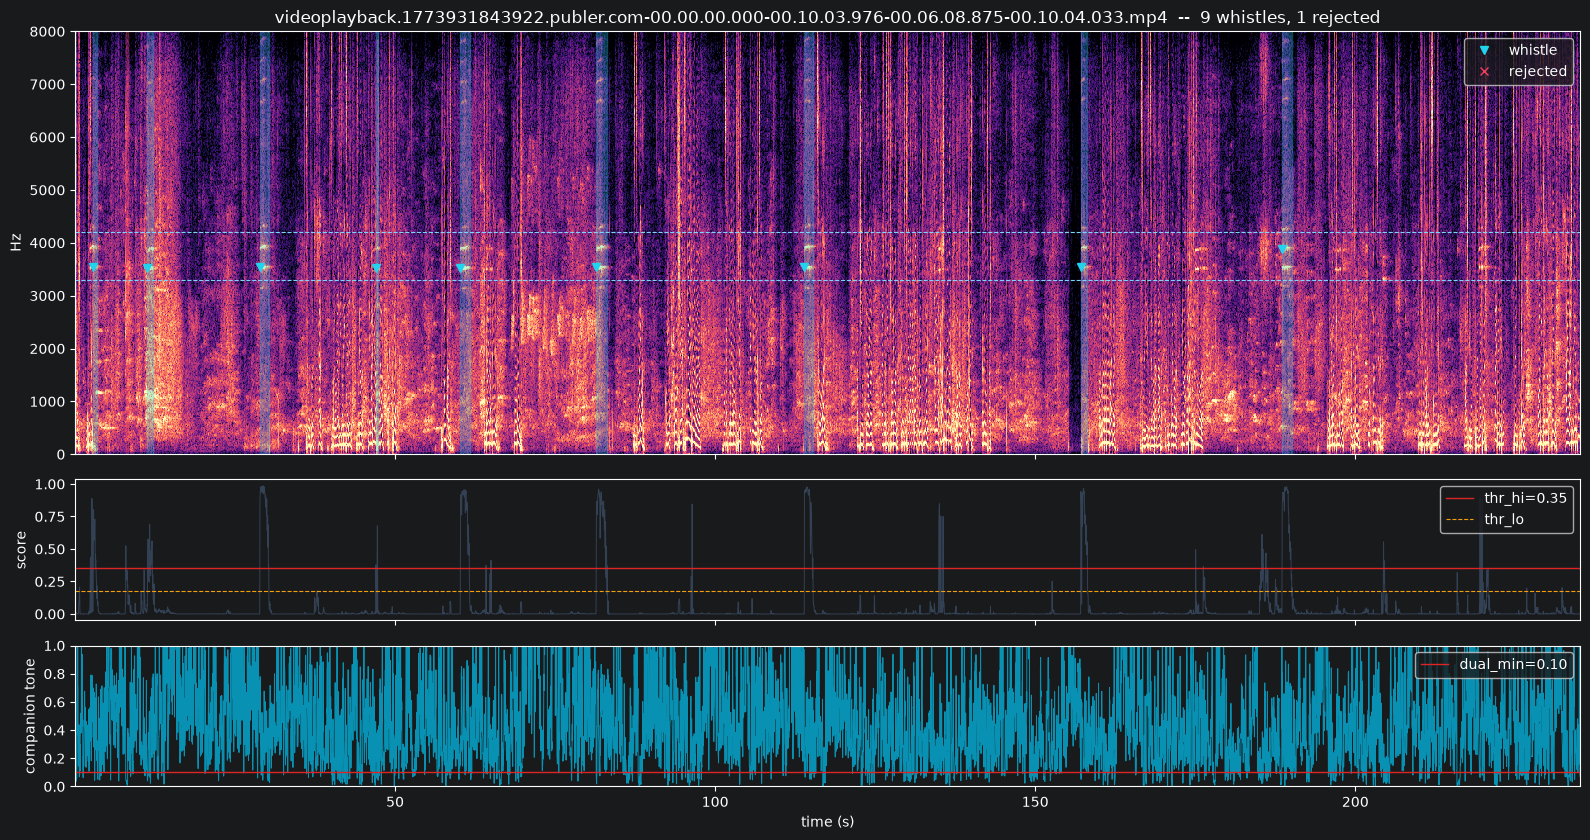

In [12]:
fig, (ax0, ax1, ax2) = plt.subplots(
    3, 1, figsize=(16, 8.5), sharex=True, gridspec_kw={"height_ratios": [3, 1, 1]}
)

S_db = 10 * np.log10(feat["P"] + 1e-20)
ax0.pcolormesh(feat["t"], feat["f"], S_db, shading="auto", cmap="magma",
               vmin=np.percentile(S_db, 5), vmax=np.percentile(S_db, 99.5))
ax0.axhline(PARAMS["f_lo"], color="#7dd3fc", lw=0.8, ls="--")
ax0.axhline(PARAMS["f_hi"], color="#7dd3fc", lw=0.8, ls="--")
ax0.set_ylim(0, PARAMS["sr"] / 2)
ax0.set_ylabel("Hz")
ax0.set_title(f"{VIDEO_PATH.name}  --  {len(events)} whistles, {len(rejected)} rejected")

KEEP, DROP = "#22d3ee", "#f43f5e"
for df, colour, mark in ((events, KEEP, "v"), (rejected, DROP, "x")):
    for r in df.itertuples():
        ax0.axvspan(r.start_s, r.end_s, color=colour, alpha=0.25)
        ax0.plot(r.start_s, r.peak_hz, marker=mark, color=colour, ms=6)
ax0.plot([], [], marker="v", ls="", color=KEEP, label="whistle")
ax0.plot([], [], marker="x", ls="", color=DROP, label="rejected")
ax0.legend(loc="upper right")

ax1.plot(feat["t"], feat["score"], lw=0.7, color="#334155")
ax1.axhline(feat["thr_hi"], color="#dc2626", lw=1.0, label=f"thr_hi={feat['thr_hi']:.2f}")
ax1.axhline(feat["thr_lo"], color="#f59e0b", lw=0.8, ls="--", label="thr_lo")
ax1.set_ylabel("score"); ax1.legend(loc="upper right")

# The timbre panel: this is what separates a whistle from a scream.
ax2.plot(feat["t"], dual, lw=0.7, color="#0891b2")
ax2.axhline(PARAMS["dual_min"], color="#dc2626", lw=1.0,
            label=f"dual_min={PARAMS['dual_min']:.2f}")
ax2.set_ylim(0, 1)
ax2.set_xlabel("time (s)"); ax2.set_ylabel("companion tone"); ax2.legend(loc="upper right")
fig.tight_layout()

In [13]:
# Audition every detection AND every rejection. Listening to the rejects is the point:
# a wrongly discarded whistle is otherwise invisible. As a recall check, also play a
# couple of random stretches BETWEEN detections and confirm no whistle was missed.
CLIP_PAD_S = 0.25
CLIP_DIR = OUT_DIR / "whistle_clips"
REJECT_DIR = CLIP_DIR / "rejected"
REJECT_DIR.mkdir(parents=True, exist_ok=True)

# Clip filenames encode their timestamp, so re-running with different params would leave
# orphans from the previous run sitting next to the current ones. Clear our own artifacts
# (by name pattern, never a blanket wipe -- anything else in the directory is not ours).
for stale in [*CLIP_DIR.glob("whistle_*.wav"), *REJECT_DIR.glob("rejected_*.wav")]:
    stale.unlink()

sr = PARAMS["sr"]


def audition(df: pd.DataFrame, out_dir: Path, prefix: str) -> None:
    for r in df.itertuples():
        lo = max(0, int((r.start_s - CLIP_PAD_S) * sr))
        hi = min(len(audio), int((r.end_s + CLIP_PAD_S) * sr))
        clip = audio[lo:hi]
        wavfile.write(out_dir / f"{prefix}_{r.Index:03d}_{r.start_s:07.2f}s.wav", sr, clip)
        print(f"#{r.Index:02d}  {r.start_s:7.2f}s  dur {r.duration_s:.2f}s  "
              f"{r.peak_hz:.0f} Hz  prom {r.prom_db:.1f} dB  score {r.score_max:.2f}  "
              f"dual {r.dual:.3f}")
        display(Audio(clip, rate=sr))


print(f"=== {len(events)} KEPT (should all be referee whistles) ===")
audition(events, CLIP_DIR, "whistle")

if len(rejected):
    print(f"\n=== {len(rejected)} REJECTED (should all be screams/shouts) ===")
    audition(rejected, REJECT_DIR, "rejected")

print(f"\nwrote {len(events)} clips to {CLIP_DIR} and {len(rejected)} to {REJECT_DIR}")

=== 9 KEPT (should all be referee whistles) ===
#00     2.85s  dur 0.51s  3547 Hz  prom 27.6 dB  score 0.80  dual 0.483


#01    11.32s  dur 0.86s  3516 Hz  prom 28.4 dB  score 0.69  dual 0.268


#02    28.87s  dur 1.41s  3547 Hz  prom 31.6 dB  score 0.99  dual 0.324


#03    46.98s  dur 0.28s  3516 Hz  prom 25.6 dB  score 0.68  dual 0.177


#04    60.19s  dur 1.44s  3531 Hz  prom 32.3 dB  score 0.96  dual 0.361


#05    81.40s  dur 1.77s  3547 Hz  prom 31.2 dB  score 0.96  dual 0.437


#06   113.93s  dur 1.36s  3547 Hz  prom 35.1 dB  score 0.98  dual 0.318


#07   157.10s  dur 1.06s  3547 Hz  prom 31.0 dB  score 0.97  dual 0.353


#08   188.55s  dur 1.51s  3891 Hz  prom 31.0 dB  score 0.98  dual 0.272



=== 1 REJECTED (should all be screams/shouts) ===
#00     7.91s  dur 0.33s  3531 Hz  prom 23.2 dB  score 0.52  dual 0.034



wrote 9 clips to /home/bugslayer/Downloads/volley video footage/data/splits/whistle_clips and 1 to /home/bugslayer/Downloads/volley video footage/data/splits/whistle_clips/rejected


In [14]:
def events_to_segments(events: pd.DataFrame, duration_s: float, params: dict,
                       fps: float, video_path: Path, out_dir: Path) -> pd.DataFrame:
    """Every whistle is a cut boundary; the segments tile the whole video end to end.

    Each cut lands `pre_roll_s` BEFORE a whistle, so every segment after the first opens
    with its own boundary whistle -- which makes the split trivially checkable by ear.
    """
    pre_roll, min_seg = params["pre_roll_s"], params["min_segment_s"]

    cuts = [0.0]
    triggers: dict[float, float] = {}
    for start_s in events["start_s"]:
        c = round(max(0.0, float(start_s) - pre_roll), 3)
        # Absorb a boundary that would produce a sub-min_segment_s fragment (double
        # blasts, back-to-back detections) into the segment already in progress.
        if c - cuts[-1] < min_seg:
            continue
        cuts.append(c)
        triggers[c] = float(start_s)
    cuts.append(round(duration_s, 3))

    stem = video_path.stem
    rows = []
    for i, (a, b) in enumerate(zip(cuts, cuts[1:])):
        rows.append({
            "segment_id": i,
            "start_s": a,
            "end_s": b,
            "duration_s": round(b - a, 3),
            "start_frame": int(round(a * fps)),
            "end_frame": int(round(b * fps)),
            "trigger_whistle_s": triggers.get(a, float("nan")),  # whistle opening this segment
            "out_path": str(out_dir / f"{stem}__seg{i:03d}__{a:07.2f}-{b:07.2f}.mp4"),
        })
    return pd.DataFrame(rows)


segments = events_to_segments(events, meta["duration_s"], PARAMS, meta["fps"], VIDEO_PATH, OUT_DIR)
assert segments["start_s"].is_monotonic_increasing
assert (segments["duration_s"] > 0).all()
assert abs(segments["duration_s"].sum() - meta["duration_s"]) < 0.01, "segments must tile the video"
print(f"{len(segments)} segments, {segments['duration_s'].sum():.2f} s total")
segments[["segment_id", "start_s", "end_s", "duration_s", "trigger_whistle_s"]]

10 segments, 235.16 s total


,segment_id,start_s,end_s,duration_s,trigger_whistle_s
0,0,0.000,2.352,2.352,NaN
1,1,2.352,10.822,8.470,2.852
2,2,10.822,28.372,17.550,11.322
3,3,28.372,46.482,18.110,28.872
4,4,46.482,59.692,13.210,46.982
5,5,59.692,80.902,21.210,60.192
6,6,80.902,113.432,32.530,81.402
7,7,113.432,156.602,43.170,113.932
8,8,156.602,188.052,31.450,157.102
9,9,188.052,235.158,47.106,188.552


In [15]:
AAC_FRAME_SIZE = 1024  # codec_context.frame_size is only valid after the encoder opens


def cut_segment(src: Path, dst: Path, start_s: float, end_s: float, params: dict) -> None:
    """Re-encode [start_s, end_s) into `dst`, frame-accurately.

    Stream copy is deliberately not the default: H.264 can only start on an IDR keyframe,
    and this footage has a multi-second GOP, so a copied cut would either open seconds
    early (leaking the previous rally) or open on macroblock garbage -- which defeats the
    point of cutting *at* the whistle. Re-encoding 640x360 at veryfast/crf20 costs seconds
    for the whole match and one negligible generation of loss.
    """
    dst.parent.mkdir(parents=True, exist_ok=True)

    with av.open(str(src)) as inp, av.open(str(dst), mode="w") as out:
        iv = inp.streams.video[0]
        iv.thread_type = "AUTO"
        ia = inp.streams.audio[0] if inp.streams.audio else None

        fps = Fraction(iv.average_rate).limit_denominator(100_000)
        ov = out.add_stream("libx264", rate=fps)
        ov.width, ov.height = iv.codec_context.width, iv.codec_context.height
        ov.pix_fmt = "yuv420p"
        # Explicit pts on an explicit time_base. Leaving frame.pts as None makes libx264
        # emit a run of zero-pts packets and then jump, which the mp4 muxer rejects.
        ov.codec_context.time_base = Fraction(1, 90_000)
        ov.codec_context.options = {"crf": str(params["crf"]), "preset": params["preset"]}
        vtb = ov.codec_context.time_base

        oa = fifo = resampler = None
        atb = None
        asamples = 0
        if ia is not None:
            rate = ia.codec_context.rate
            oa = out.add_stream("aac", rate=rate)
            oa.bit_rate = params["audio_bitrate"]
            atb = Fraction(1, rate)
            oa.codec_context.time_base = atb
            resampler = av.AudioResampler(
                format=oa.codec_context.format, layout=oa.layout, rate=rate
            )
            fifo = av.AudioFifo()

        def drain(flush: bool = False) -> None:
            nonlocal asamples
            while True:
                af = fifo.read(AAC_FRAME_SIZE, partial=flush)
                if af is None:
                    break
                af.pts, af.time_base = asamples, atb
                asamples += af.samples
                for pkt in oa.encode(af):
                    out.mux(pkt)
                if flush and af.samples < AAC_FRAME_SIZE:
                    break

        # Seek to the keyframe at or before start_s so each segment decodes only the
        # tail of the file it needs; frames before start_s are decoded then dropped.
        inp.seek(int(start_s / iv.time_base), stream=iv, backward=True, any_frame=False)

        streams = [s for s in (iv, ia) if s is not None]
        v_done = a_done = False
        for packet in inp.demux(streams):
            if v_done and (a_done or oa is None):
                break
            for frame in packet.decode():
                if frame.pts is None:
                    continue
                ts = float(frame.pts * frame.time_base)
                if isinstance(frame, av.VideoFrame):
                    if v_done or ts < start_s:
                        continue
                    if ts >= end_s:
                        v_done = True
                        continue
                    frame.pts = int(round((ts - start_s) / vtb))
                    frame.time_base = vtb
                    frame.pict_type = av.video.frame.PictureType.NONE
                    for pkt in ov.encode(frame):
                        out.mux(pkt)
                elif oa is not None:
                    if a_done or ts + frame.samples / frame.rate <= start_s:
                        continue
                    if ts >= end_s:
                        a_done = True
                        continue
                    for r in resampler.resample(frame):
                        r.pts = None
                        fifo.write(r)
                    drain()

        for pkt in ov.encode(None):
            out.mux(pkt)
        if oa is not None:
            for r in resampler.resample(None):
                r.pts = None
                fifo.write(r)
            drain(flush=True)
            for pkt in oa.encode(None):
                out.mux(pkt)

In [16]:
assert not PARAMS["stream_copy"], "cut_segment only implements the re-encode path"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Segment filenames encode their cut points, so a re-run with different params does NOT
# overwrite the old set -- it interleaves with it. Drop our own leftovers first, matching
# only this video's segment pattern.
current = {Path(r.out_path).name for r in segments.itertuples()}
for stale in OUT_DIR.glob(f"{VIDEO_PATH.stem}__seg*.mp4"):
    if stale.name not in current:
        print(f"removing stale segment {stale.name.split('__', 1)[1]}")
        stale.unlink()

for r in tqdm(list(segments.itertuples()), desc="cutting"):
    cut_segment(VIDEO_PATH, Path(r.out_path), r.start_s, r.end_s, PARAMS)

print(f"wrote {len(segments)} segments to {OUT_DIR}")

cutting: 100%|██████████| 10/10 [00:17<00:00,  1.79s/it]

wrote 10 segments to /home/bugslayer/Downloads/volley video footage/data/splits


In [17]:
events.to_csv(OUT_DIR / "whistles.csv", index=False)
segments.to_csv(OUT_DIR / "segments.csv", index=False)
(OUT_DIR / "params.json").write_text(json.dumps({"video": str(VIDEO_PATH), **PARAMS}, indent=2))

checks = []
for r in tqdm(list(segments.itertuples()), desc="verifying"):
    m = probe_video(r.out_path)
    with av.open(r.out_path) as c:
        first = next(c.decode(c.streams.video[0]))
    checks.append({
        "segment_id": r.segment_id,
        "expected_s": r.duration_s,
        "actual_s": round(m["duration_s"], 3),
        "delta_s": round(m["duration_s"] - r.duration_s, 3),
        "size": f"{m['width']}x{m['height']}",
        "fps": round(m["fps"], 3),
        "has_audio": m["has_audio"],
        "first_frame_ok": (first.width, first.height) == (m["width"], m["height"]),
        "mb": round(Path(r.out_path).stat().st_size / 1e6, 2),
    })

report = pd.DataFrame(checks)
assert report["delta_s"].abs().max() < 0.1, report[report["delta_s"].abs() >= 0.1]
assert report["has_audio"].all() and report["first_frame_ok"].all()
assert (report["size"] == f"{meta['width']}x{meta['height']}").all()
on_disk = len(list(OUT_DIR.glob(f"{VIDEO_PATH.stem}__seg*.mp4")))
assert on_disk == len(segments), f"{on_disk} segment files on disk but {len(segments)} expected"
print(f"all {len(report)} segments verified  (max duration delta "
      f"{report['delta_s'].abs().max():.3f} s, {report['mb'].sum():.1f} MB total)")
report

verifying: 100%|██████████| 10/10 [00:00<00:00, 68.25it/s]

all 10 segments verified  (max duration delta 0.039 s, 16.5 MB total)


,segment_id,expected_s,actual_s,delta_s,size,fps,has_audio,first_frame_ok,mb
0,0,2.352,2.391,0.039,640x360,29.851,True,True,0.16
1,1,8.470,8.498,0.028,640x360,30.000,True,True,0.59
2,2,17.550,17.577,0.027,640x360,30.000,True,True,1.25
3,3,18.110,18.135,0.025,640x360,30.000,True,True,1.22
4,4,13.210,13.242,0.032,640x360,30.000,True,True,0.98
5,5,21.210,21.232,0.022,640x360,30.000,True,True,1.44
6,6,32.530,32.555,0.025,640x360,30.000,True,True,2.12
7,7,43.170,43.193,0.023,640x360,30.000,True,True,3.27
8,8,31.450,31.486,0.036,640x360,30.000,True,True,2.21
9,9,47.106,47.073,-0.033,640x360,30.000,True,True,3.27
